# Intrusion-Risk Prediction Model

Supervised **binary** model: predicts the probability (0 to 1) that a network flow is malicious, then maps it to a
risk level (Low / Medium / High / Critical).

- Same 24 features as the other models (`dst_port` excluded), duplicates removed.
- Split 60 / 20 / 20 (train / calibration / test), stratified on the **original attack label** so rare attacks appear in every set.
- Random Forest vs HistGradientBoosting compared with 5-fold CV; the winner is calibrated (isotonic) so probabilities are trustworthy.
- Decision threshold chosen by F2 (recall weighted higher: a missed attack costs more than a false alarm).
- CPU is capped at 2 threads so other jobs running in parallel are not slowed down.

In [1]:
import json
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from threadpoolctl import threadpool_limits

# Locate the repository root so the notebook runs from any checkout location.
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "requirements.txt").exists() and (p / "src").is_dir()
)

DATA_PATH = PROJECT_ROOT / "data" / "cleaned_network_data" / "cleaned_network_data.csv"
MODEL_DIR = PROJECT_ROOT / "ml" / "models"
RANDOM_STATE = 42
N_JOBS = 2

# Cap OpenMP/BLAS threads (HistGradientBoosting would otherwise use every core).
threadpool_limits(N_JOBS)

RISK_BANDS = [  # (level, lower bound of calibrated probability)
    ("Critical", 0.90),
    ("High", 0.70),
    ("Medium", 0.30),
    ("Low", 0.0),
]

## 1. Load data, select features, remove duplicates

In [2]:
df = pd.read_csv(DATA_PATH)
FEATURES = [c for c in df.columns if c not in ("label", "dst_port")]

before = len(df)
df = df.drop_duplicates(subset=FEATURES).reset_index(drop=True)
df["is_intrusion"] = (df["label"] != "BENIGN").astype(int)

print("Features used:", len(FEATURES))
print(f"Rows: {before:,} -> {len(df):,} (removed {before - len(df):,} duplicate feature vectors)")
print(df["is_intrusion"].value_counts().rename({0: "BENIGN (0)", 1: "intrusion (1)"}))

Features used: 24
Rows: 97,548 -> 87,222 (removed 10,326 duplicate feature vectors)
is_intrusion
BENIGN (0)       49834
intrusion (1)    37388
Name: count, dtype: int64


## 2. Split 60 / 20 / 20, stratified on the attack label

In [3]:
train_df, rest_df = train_test_split(df, test_size=0.4, random_state=RANDOM_STATE, stratify=df["label"])
cal_df, test_df = train_test_split(rest_df, test_size=0.5, random_state=RANDOM_STATE, stratify=rest_df["label"])

X_train, y_train = train_df[FEATURES], train_df["is_intrusion"]
X_cal, y_cal = cal_df[FEATURES], cal_df["is_intrusion"]
X_test, y_test = test_df[FEATURES], test_df["is_intrusion"]

split_summary = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "calibration": cal_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
})
print(split_summary.to_string())
print()
print("Totals:", len(train_df), len(cal_df), len(test_df))

                            train  calibration  test
label                                               
BENIGN                      29900         9967  9967
DDoS                         4706         1568  1569
DoS Hulk                     4691         1564  1564
DoS GoldenEye                3148         1049  1049
FTP-Patator                  2555          851   852
SSH-Patator                  1889          630   630
DoS slowloris                1579          526   527
DoS Slowhttptest             1550          517   517
Bot                           854          285   285
Web Attack - Brute Force      794          265   264
Web Attack - XSS              391          130   130
PortScan                      235           79    78
Infiltration                   22            7     7
Web Attack - Sql Injection     12            4     4
Heartbleed                      7            2     2

Totals: 52333 17444 17445


## 3. Compare candidate models with 5-fold CV on the training set

In [4]:
CANDIDATES = {
    "RandomForest": lambda: RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    ),
    "HistGradientBoosting": lambda: HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.1,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# Stratify folds on the attack label (not just 0/1) so rare attacks land in every fold.
folds = list(skf.split(X_train, train_df["label"]))

cv_rows = []
for name, make_model in CANDIDATES.items():
    res = cross_validate(
        make_model(), X_train, y_train, cv=folds,
        scoring=["roc_auc", "average_precision", "recall", "precision"],
    )
    cv_rows.append({
        "model": name,
        "roc_auc": res["test_roc_auc"].mean(),
        "pr_auc": res["test_average_precision"].mean(),
        "recall": res["test_recall"].mean(),
        "precision": res["test_precision"].mean(),
        "roc_auc_std": res["test_roc_auc"].std(),
        "fit_time_s": res["fit_time"].mean(),
    })

cv_results = pd.DataFrame(cv_rows).set_index("model")
print(cv_results.round(5).to_string())

                      roc_auc   pr_auc   recall  precision  roc_auc_std  fit_time_s
model                                                                              
RandomForest          0.99876  0.99709  0.99073    0.99401      0.00033     5.76870
HistGradientBoosting  0.99973  0.99965  0.99661    0.99228      0.00004     1.99848


In [5]:
# Pick the best PR-AUC; if the gap is tiny (< 0.001) prefer Random Forest (simpler to explain).
best = cv_results["pr_auc"].idxmax()
if best != "RandomForest" and cv_results.loc[best, "pr_auc"] - cv_results.loc["RandomForest", "pr_auc"] < 0.001:
    best = "RandomForest"

BEST_MODEL = best
print("Selected model:", BEST_MODEL)

Selected model: HistGradientBoosting


## 4. Fit the selected model and calibrate probabilities on the calibration set

In [6]:
base_model = CANDIDATES[BEST_MODEL]().fit(X_train, y_train)

calibrated = CalibratedClassifierCV(FrozenEstimator(base_model), method="isotonic")
calibrated.fit(X_cal, y_cal)

raw_test_proba = base_model.predict_proba(X_test)[:, 1]
test_proba = calibrated.predict_proba(X_test)[:, 1]

print(f"Brier score raw       : {brier_score_loss(y_test, raw_test_proba):.5f}")
print(f"Brier score calibrated: {brier_score_loss(y_test, test_proba):.5f}  (lower is better)")

Brier score raw       : 0.00377
Brier score calibrated: 0.00377  (lower is better)


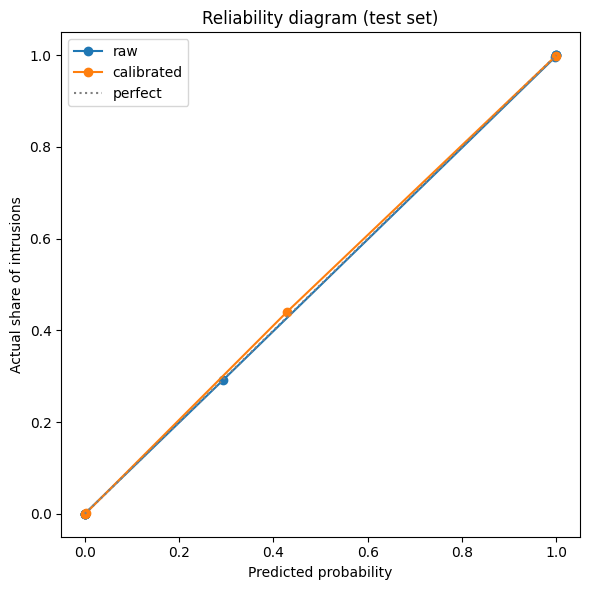

In [7]:
plt.figure(figsize=(6, 6))
for label, proba in [("raw", raw_test_proba), ("calibrated", test_proba)]:
    frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac_pos, marker="o", label=label)
plt.plot([0, 1], [0, 1], color="grey", linestyle=":", label="perfect")
plt.xlabel("Predicted probability")
plt.ylabel("Actual share of intrusions")
plt.title("Reliability diagram (test set)")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Decision threshold (F2) and risk levels

The yes/no `is_intrusion` threshold maximises F2 on the **calibration** set. Risk levels use fixed probability bands
(valid because the probabilities are calibrated).

In [8]:
cal_proba = calibrated.predict_proba(X_cal)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_cal, cal_proba)

beta = 2
f2 = (1 + beta**2) * precision[:-1] * recall[:-1] / np.clip(beta**2 * precision[:-1] + recall[:-1], 1e-12, None)
best_idx = int(np.argmax(f2))
DECISION_THRESHOLD = float(thresholds[best_idx])

print(f"F2-optimal threshold: {DECISION_THRESHOLD:.4f}")
print(f"  calibration precision: {precision[best_idx]:.4f}  recall: {recall[best_idx]:.4f}  F2: {f2[best_idx]:.4f}")


def risk_level(proba):
    proba = np.asarray(proba)
    return np.select(
        [proba >= lo for _, lo in RISK_BANDS[:-1]],
        [name for name, _ in RISK_BANDS[:-1]],
        default=RISK_BANDS[-1][0],
    )


cal_levels = pd.crosstab(
    cal_df["is_intrusion"].map({0: "BENIGN", 1: "intrusion"}),
    pd.Series(risk_level(cal_proba), index=cal_df.index, name="risk_level"),
).reindex(columns=["Low", "Medium", "High", "Critical"], fill_value=0)
print()
print("Risk-level counts on the calibration set:")
print(cal_levels.to_string())

F2-optimal threshold: 0.4062
  calibration precision: 0.9899  recall: 0.9984  F2: 0.9967

Risk-level counts on the calibration set:
risk_level     Low  Medium  High  Critical
is_intrusion                              
BENIGN        9891      25    27        24
intrusion       12      23   187      7255


## 6. Evaluate on the test set

In [9]:
test_pred = (test_proba >= DECISION_THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()

metrics = {
    "roc_auc": roc_auc_score(y_test, test_proba),
    "pr_auc": average_precision_score(y_test, test_proba),
    "recall": recall_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred),
    "f1": f1_score(y_test, test_pred),
    "false_alarm_rate": fp / (fp + tn),
    "brier": brier_score_loss(y_test, test_proba),
}

for name, value in metrics.items():
    print(f"{name:18}: {value:.4f}")
print()
print(f"Confusion matrix: TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

roc_auc           : 0.9997
pr_auc            : 0.9996
recall            : 0.9979
precision         : 0.9908
f1                : 0.9943
false_alarm_rate  : 0.0069
brier             : 0.0038

Confusion matrix: TN=9,898  FP=69  FN=16  TP=7,462


In [10]:
# Per attack type: share detected, mean risk probability, and spread across risk levels.
test_df = test_df.assign(risk_probability=test_proba, predicted=test_pred, risk_level=risk_level(test_proba))

per_class = test_df.groupby("label").agg(
    rows=("predicted", "size"),
    flagged_as_intrusion=("predicted", "mean"),
    mean_probability=("risk_probability", "mean"),
)
levels = pd.crosstab(test_df["label"], test_df["risk_level"], normalize="index").reindex(
    columns=["Low", "Medium", "High", "Critical"], fill_value=0
)
per_class = per_class.join(levels).sort_values("flagged_as_intrusion")

print(per_class.round(3).to_string())

                            rows  flagged_as_intrusion  mean_probability    Low  Medium   High  Critical
label                                                                                                   
BENIGN                      9967                 0.007             0.006  0.993   0.003  0.002     0.003
Infiltration                   7                 0.714             0.607  0.286   0.143  0.000     0.571
Web Attack - XSS             130                 0.977             0.876  0.015   0.023  0.577     0.385
Bot                          285                 0.986             0.952  0.014   0.021  0.039     0.926
Web Attack - Brute Force     264                 0.989             0.900  0.011   0.008  0.455     0.527
DoS slowloris                527                 0.996             0.995  0.004   0.000  0.004     0.992
DoS Hulk                    1564                 0.999             0.997  0.001   0.003  0.002     0.994
DoS GoldenEye               1049                 1.000 

## 7. Unseen-attack test (hide one attack family)

Retrain the selected model **without** one attack family, then check whether that family still gets a high risk score.
Compared against the anomaly detector (Medium or High) on the same rows.

In [11]:
anomaly_model = joblib.load(MODEL_DIR / "anomaly_detector.pkl")
anomaly_meta = json.loads((MODEL_DIR / "anomaly_detector_meta.json").read_text())

HIDDEN_FAMILIES = ["Web Attack", "Infiltration", "PortScan"]
unseen_rows = []

for family in HIDDEN_FAMILIES:
    keep = ~train_df["label"].str.startswith(family)
    model_wo = CANDIDATES[BEST_MODEL]().fit(X_train[keep], y_train[keep])

    family_test = test_df[test_df["label"].str.startswith(family)]
    proba_wo = model_wo.predict_proba(family_test[FEATURES])[:, 1]
    anomaly_scores = -anomaly_model.score_samples(family_test[anomaly_meta["features"]])

    unseen_rows.append({
        "hidden_family": family,
        "test_rows": len(family_test),
        "risk_model_detected (p>=0.5)": (proba_wo >= 0.5).mean(),
        "risk_model_mean_prob": proba_wo.mean(),
        "anomaly_flagged (Medium+)": (anomaly_scores >= anomaly_meta["thresholds"]["medium"]).mean(),
        "full_model_detected": test_df.loc[family_test.index, "predicted"].mean(),
    })

unseen = pd.DataFrame(unseen_rows).set_index("hidden_family")
print(unseen.round(3).to_string())

               test_rows  risk_model_detected (p>=0.5)  risk_model_mean_prob  anomaly_flagged (Medium+)  full_model_detected
hidden_family                                                                                                               
Web Attack           398                         0.028                 0.027                      0.000                0.985
Infiltration           7                         0.000                 0.004                      0.714                0.714
PortScan              78                         0.218                 0.195                      0.628                1.000


## 8. Feature importance (permutation, on a test sample)

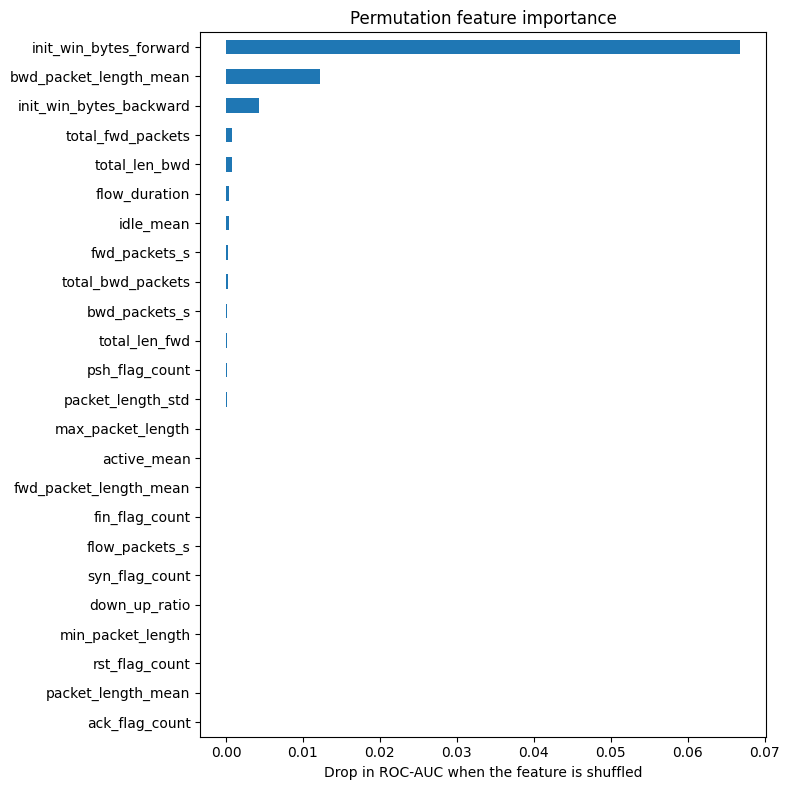

init_win_bytes_forward     0.06680
bwd_packet_length_mean     0.01224
init_win_bytes_backward    0.00428
total_fwd_packets          0.00079
total_len_bwd              0.00076
flow_duration              0.00046
idle_mean                  0.00039
fwd_packets_s              0.00026
total_bwd_packets          0.00021
bwd_packets_s              0.00015
total_len_fwd              0.00012
psh_flag_count             0.00010
packet_length_std          0.00010
max_packet_length          0.00007
active_mean                0.00006
fwd_packet_length_mean     0.00006
fin_flag_count             0.00005
flow_packets_s             0.00005
syn_flag_count             0.00003
down_up_ratio              0.00002
min_packet_length          0.00000
rst_flag_count             0.00000
packet_length_mean        -0.00000
ack_flag_count            -0.00001


In [12]:
sample = test_df.sample(n=min(5000, len(test_df)), random_state=RANDOM_STATE)

perm = permutation_importance(
    calibrated, sample[FEATURES], sample["is_intrusion"],
    scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE,
)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

plt.figure(figsize=(8, 8))
importance.plot.barh()
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.title("Permutation feature importance")
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False).round(5).to_string())

## 9. Save model and metadata

In [13]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "intrusion_risk.pkl"
meta_path = MODEL_DIR / "intrusion_risk_meta.json"

joblib.dump(calibrated, model_path)

meta = {
    "model": f"CalibratedClassifierCV(isotonic) over {BEST_MODEL}",
    "trained_at": datetime.now().isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
    "data_file": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "excluded_columns": ["dst_port"],
    "features": FEATURES,
    "target": "is_intrusion (0 = BENIGN, 1 = any attack)",
    "output": "risk_probability = model.predict_proba(X)[:, 1]",
    "decision_threshold": round(DECISION_THRESHOLD, 6),
    "risk_bands": {name: lo for name, lo in RISK_BANDS},
    "base_params": base_model.get_params(),
    "cv_results": cv_results.round(5).reset_index().to_dict(orient="records"),
    "n_train": len(train_df),
    "n_calibration": len(cal_df),
    "n_test": len(test_df),
    "test_metrics": {k: round(float(v), 5) for k, v in metrics.items()},
    "per_class_detection": per_class["flagged_as_intrusion"].round(4).to_dict(),
    "unseen_attack_test": unseen.round(4).reset_index().to_dict(orient="records"),
    "top_features": importance.sort_values(ascending=False).head(10).round(5).to_dict(),
}
meta_path.write_text(json.dumps(meta, indent=2, default=str))

print("Saved:", model_path)
print("Saved:", meta_path)

Saved: D:\Cybersecurity-assistant\ml\models\intrusion_risk.pkl
Saved: D:\Cybersecurity-assistant\ml\models\intrusion_risk_meta.json


## 10. Load-and-predict check

In [14]:
loaded = joblib.load(model_path)
loaded_meta = json.loads(meta_path.read_text())

samples = test_df.groupby("label").head(1)
proba = loaded.predict_proba(samples[loaded_meta["features"]])[:, 1]

check = pd.DataFrame({
    "label": samples["label"].values,
    "risk_probability": proba.round(3),
    "is_intrusion": proba >= loaded_meta["decision_threshold"],
    "risk_level": risk_level(proba),
})
print(check.to_string(index=False))

                     label  risk_probability  is_intrusion risk_level
             DoS GoldenEye             1.000          True   Critical
               SSH-Patator             1.000          True   Critical
                  DoS Hulk             1.000          True   Critical
                    BENIGN             0.000         False        Low
                      DDoS             1.000          True   Critical
  Web Attack - Brute Force             0.873          True       High
             DoS slowloris             0.998          True   Critical
          Web Attack - XSS             0.931          True   Critical
          DoS Slowhttptest             1.000          True   Critical
                       Bot             1.000          True   Critical
               FTP-Patator             1.000          True   Critical
                  PortScan             0.998          True   Critical
              Infiltration             0.005         False        Low
                Hear

## 11. Test with custom data

Edit the values in `custom_flow` and run the two cells below.
No retraining needed: after a kernel restart, run only the **first cell** (imports and paths) and then these cells.

Tip: to start from a real flow instead, use `custom_flow = X_test.iloc[0].to_dict()` (requires the earlier cells to have run).

In [15]:
# Edit any value below. The example is a real PortScan flow from CIC-IDS2017.
custom_flow = {
    "flow_duration": 46.0,
    "total_fwd_packets": 1.0,
    "total_bwd_packets": 1.0,
    "total_len_fwd": 2.0,
    "total_len_bwd": 6.0,
    "flow_packets_s": 43478.26087,
    "fwd_packets_s": 21739.13043,
    "bwd_packets_s": 21739.13043,
    "fwd_packet_length_mean": 2.0,
    "bwd_packet_length_mean": 6.0,
    "min_packet_length": 2.0,
    "max_packet_length": 6.0,
    "packet_length_mean": 3.333333,
    "packet_length_std": 2.309401,
    "syn_flag_count": 0.0,
    "ack_flag_count": 0.0,
    "rst_flag_count": 0.0,
    "psh_flag_count": 1.0,
    "fin_flag_count": 0.0,
    "down_up_ratio": 1.0,
    "init_win_bytes_forward": 1024.0,
    "init_win_bytes_backward": 0.0,
    "active_mean": 0.0,
    "idle_mean": 0.0,
}

In [16]:
saved_model = joblib.load(MODEL_DIR / "intrusion_risk.pkl")
saved_meta = json.loads((MODEL_DIR / "intrusion_risk_meta.json").read_text())


def predict_risk(flow):
    features = saved_meta["features"]
    missing = [f for f in features if f not in flow]
    if missing:
        raise ValueError(f"Missing features: {missing}")
    extra = [f for f in flow if f not in features]
    if extra:
        print("Ignoring unknown fields:", extra)

    row = pd.DataFrame([flow])[features]
    proba = float(saved_model.predict_proba(row)[0, 1])
    bands = sorted(saved_meta["risk_bands"].items(), key=lambda kv: kv[1], reverse=True)
    level = next(name for name, lo in bands if proba >= lo)
    is_intrusion = proba >= saved_meta["decision_threshold"]

    print(f"Risk probability: {proba:.3f}")
    print(f"Intrusion?      : {'YES' if is_intrusion else 'no'}")
    print(f"Risk level      : {level}")
    return {"risk_probability": proba, "is_intrusion": is_intrusion, "risk_level": level}


predict_risk(custom_flow);

Risk probability: 0.981
Intrusion?      : YES
Risk level      : Critical
